# 📊 Predicción de Churn con XGBoost y SHAP


En este notebook abordaremos un problema clásico de negocio: **Customer Churn (Fuga de Clientes)** en una empresa de Telecomunicaciones.
El objetivo no es solo predecir *quién* se va, sino entender *por qué* se va, utilizando **XGBoost** para el modelado y **SHAP** (SHapley Additive exPlanations) para explicabilidad.

## 🎯 Fases del Proyecto:
1. **EDA & Análisis de Fuga**: Exploración de la tasa base de churn y variables clave.
2. **Preprocesamiento & Pipelines**: Preparación de datos para modelos de Machine Learning.
3. **Modelado**: Comparación entre un modelo base (Regresión Logística) y XGBoost.
4. **Explicabilidad con SHAP**: Interpretabilidad global y local para decisiones de negocio.


---
## 🔍 Fase 1: EDA & Análisis de Fuga
Primero, vamos a cargar nuestros datos y explorar su estructura.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Cargar dataset
df = pd.read_csv('../data/raw/Telco-Customer-Churn.csv')

# Vistazo rápido
display(df.head())
print(f"\nDimensiones del dataset: {df.shape}")


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Dimensiones del dataset: (7043, 21)


Tasa base de Churn: 26.58%


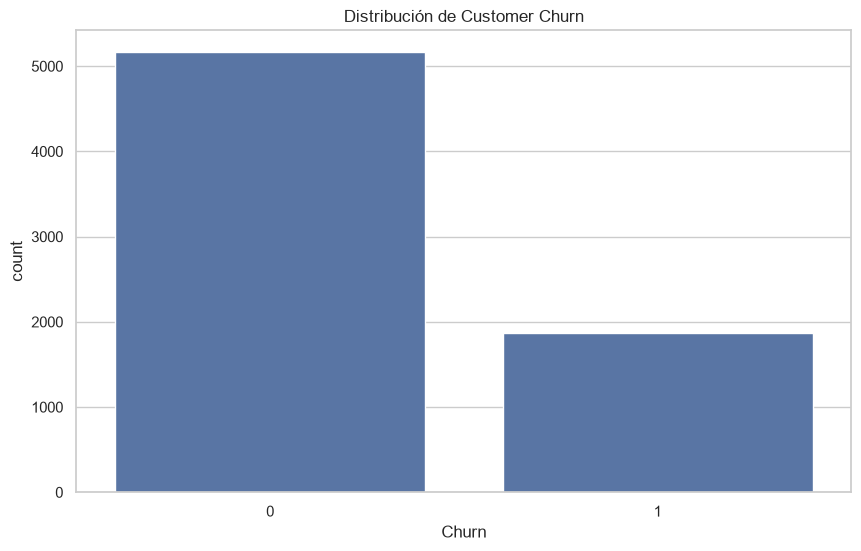

In [2]:
# Limpieza básica: TotalCharges viene como string en el dataset original
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df.dropna(subset=['TotalCharges'], inplace=True) # Eliminamos 11 filas nulas
df.drop('customerID', axis=1, inplace=True)

# Transformar variable objetivo a binaria (0/1)
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

# Tasa base de Churn
churn_rate = df['Churn'].mean()
print(f"Tasa base de Churn: {churn_rate:.2%}")

sns.countplot(data=df, x='Churn')
plt.title("Distribución de Customer Churn")
plt.show()


---
## ⚙️ Fase 2: Preprocesamiento & Pipelines
Prepararemos los datos dividiéndolos en conjunto de entrenamiento y prueba. Usaremos codificación `One-Hot` para variables categóricas.


In [3]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Separar Features (X) y Target (y)
X = df.drop('Churn', axis=1)
y = df['Churn']

# Separación en Train y Test (estratificado por la clase desbalanceada)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Identificar columnas numéricas y categóricas
numeric_features = ['tenure', 'MonthlyCharges', 'TotalCharges']
categorical_features = X.columns.difference(numeric_features).tolist()

# Transformadores
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_features) # drop='first' evita colinealidad
    ]
)

# Aplicar preprocesamiento para ver su efecto
X_train_processed = preprocessor.fit_transform(X_train)
print(f"Features tras preprocesamiento: {X_train_processed.shape[1]}")


Features tras preprocesamiento: 30


---
## 🧠 Fase 3: Modelado & Comparativa
Construiremos dos pipelines: uno con **Regresión Logística** como línea base y otro con **XGBoost**.
Evaluaremos utilizando la métrica `ROC-AUC` y el reporte de clasificación (focalizándonos en **Recall** para detectar la mayor cantidad de clientes en riesgo).


In [4]:
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, roc_auc_score

# 1. Pipeline Regresión Logística (Base)
lr_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced'))
])

lr_pipeline.fit(X_train, y_train)
lr_preds = lr_pipeline.predict(X_test)
lr_probs = lr_pipeline.predict_proba(X_test)[:, 1]

print("=== Regresión Logística ===")
print(f"ROC-AUC: {roc_auc_score(y_test, lr_probs):.4f}")
print(classification_report(y_test, lr_preds))


=== Regresión Logística ===
ROC-AUC: 0.8353
              precision    recall  f1-score   support

           0       0.90      0.70      0.79      1033
           1       0.49      0.79      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.79      0.73      0.74      1407



In [5]:
# 2. Pipeline XGBoost (Avanzado)
xgb_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', XGBClassifier(
        n_estimators=100, 
        learning_rate=0.1, 
        max_depth=4, 
        random_state=42, 
        scale_pos_weight=len(y_train[y_train==0])/len(y_train[y_train==1]) # Balanceo de clases
    ))
])

xgb_pipeline.fit(X_train, y_train)
xgb_preds = xgb_pipeline.predict(X_test)
xgb_probs = xgb_pipeline.predict_proba(X_test)[:, 1]

print("=== XGBoost ===")
print(f"ROC-AUC: {roc_auc_score(y_test, xgb_probs):.4f}")
print(classification_report(y_test, xgb_preds))


=== XGBoost ===
ROC-AUC: 0.8383
              precision    recall  f1-score   support

           0       0.90      0.71      0.79      1033
           1       0.49      0.79      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.80      0.73      0.74      1407



---
## 💡 Fase 4: Explicabilidad con SHAP
Para usar SHAP eficientemente, extraeremos el modelo XGBoost del pipeline y calcularemos los valores SHAP sobre los datos transformados.
Esto nos dirá **qué variables tienen el mayor impacto en empujar al cliente hacia el abandono (Churn=1) o la retención (Churn=0)**.


In [6]:
import shap

# Extraer el modelo y el preprocesador
model = xgb_pipeline.named_steps['classifier']
preprocessor = xgb_pipeline.named_steps['preprocessor']

# Obtener nombres de columnas tras OneHotEncoding
cat_names = preprocessor.named_transformers_['cat'].get_feature_names_out(categorical_features)
feature_names = numeric_features + cat_names.tolist()

# Transformar X_train para el explainer
X_train_transformed = pd.DataFrame(
    preprocessor.transform(X_train), 
    columns=feature_names
)

# Configurar SHAP TreeExplainer
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_train_transformed)

print("Explainer listo!")


Explainer listo!


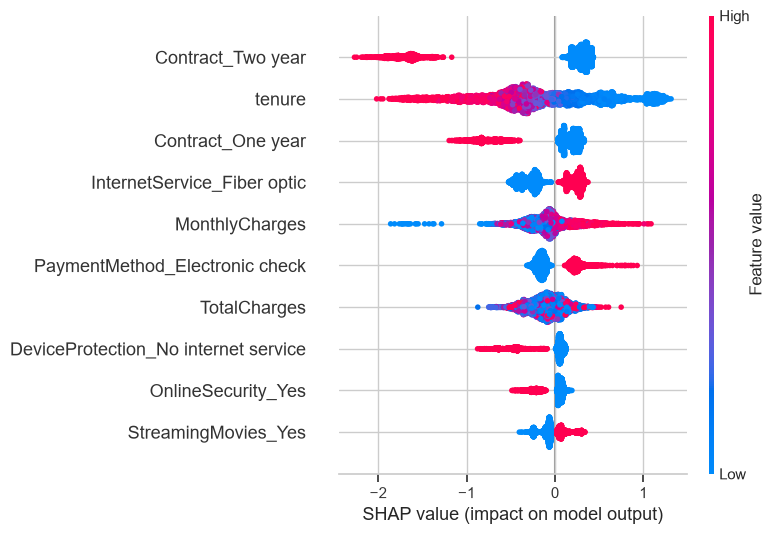

In [7]:
# 1. Importancia Global (Summary Plot)
shap.summary_plot(shap_values, X_train_transformed, max_display=10)


Hallazgos comerciales revelados:
- Los que tiene Contracto mes a mes parecen ser más riesgosos, esto implicitamente al ver la distribucion de Contract_Two year y Contract_One year donde los puntos rojos (1) se muestran en la parte izquierda demostrando que por esas caracteristicas es poco probable que desista.
- Caso similar con tenure(antiguedad) donde azul tiene poco antiguedad se encuentra en la parte derecha del modelo evidenciando que impacta en aumento de probabilidad de desistir.
- InternetSevice_Fiber optic + DeviceProtection_No internet service: los clientes con fibra optica pero sin protección/soporte tienen puntos en la parte derecha empujando a ese tipo de clientes a desistir

Cliente con 96.2% de probabilidad de Churn


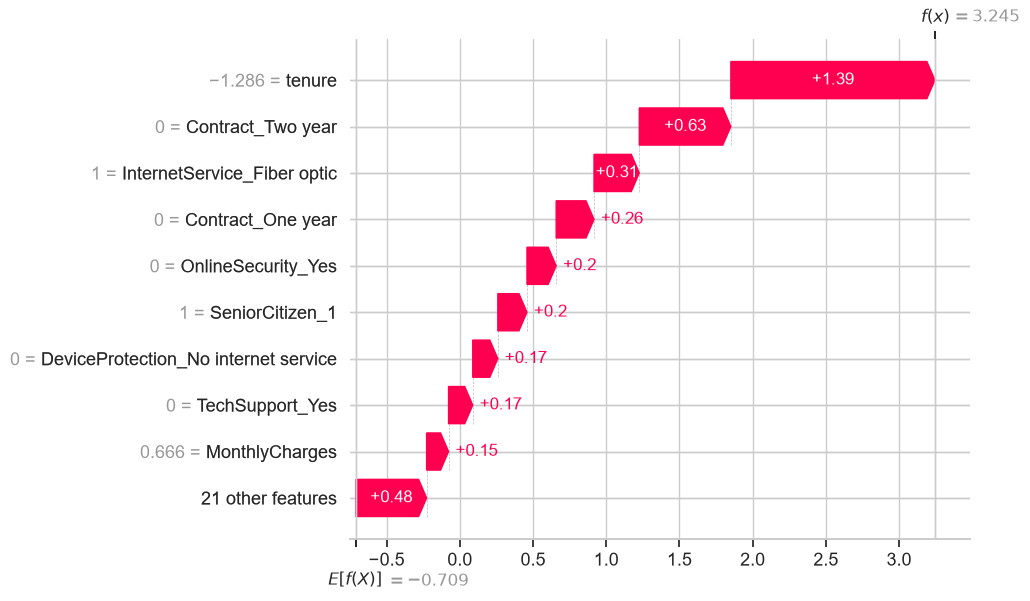

In [8]:
# 2. Importancia Local (Waterfall Plot - Cliente Individual)
# Analicemos un cliente de alto riesgo (alta probabilidad de Churn)
X_test_transformed = pd.DataFrame(
    preprocessor.transform(X_test), 
    columns=feature_names
)

# Buscar el cliente con mayor probabilidad de churn en el conjunto de prueba
idx = np.argmax(xgb_probs)

print(f"Cliente con {xgb_probs[idx]:.1%} de probabilidad de Churn")
explainer_v2 = shap.Explainer(model, X_train_transformed)
shap_values_v2 = explainer_v2(X_test_transformed)

shap.plots.waterfall(shap_values_v2[idx], max_display=10)


Este cliente con mayor probabilidad de desistir presenta varias caracteristicas como Contrato mes a mes, poca antiguedad, tiene fibra optica, no tiene seguridad en linea ni soporte ni proteccion en dispositivos.
Que valor aporta esto en el mundo real ?

Si el equipo de retención llama a este cliente y le ofrece un descuento cualquiera, probablemente no funcione. Pero el Waterfall Plot le dice al agente de soporte exactamente por qué se va:

Tiene contrato mes a mes (+ riesgo alto)
Lleva solo 1 o 2 meses de antigüedad (+ riesgo alto)
Tiene fibra óptica sin soporte técnico (+ riesgo)

Acción comercial hiper-personalizada: En lugar de darle un descuento genérico, el ejecutivo le ofrece: "Te regalamos 6 meses de soporte técnico premium gratuito si migras a un contrato anual con tarifa congelada". Atacas exactamente las variables que SHAP identificó como culpables del riesgo.